### DISCO Ablation (R4) — Compositional Soft Prompting (CSP) + KgCoOp vs. CoOp
Standalone notebook for **CSP (Nayak et al., ICLR 2023)** with **KgCoOp knowledge-guided regularization (Yao et al., CVPR 2023)** using the frozen BioCLIP ViT-B/16 backbone and cached image features (`feats_bioclip_v10.pt`), evaluated with **`seed = 42`**.
| Variant | Prompt Structure | Trainable Input Parameters | Output Anchor ($\mathcal{L}_{kg}$) |
| :--- | :--- | :--- | :--- |
| **R4 (CoOp)** | `[SOS] [ctx_1 .. ctx_M] {class} {suffix} [EOS]` | Shared prefix `ctx` (`4×512` crop + `6×512` dis = **5,120** params) | None / optional |
| **R4_CSP_noKG** | `[SOS] a photo of a [theta_k] {suffix} [EOS]` | Class primitive deltas $\Delta\theta_k$ (`61` crop + `574` dis subwords = **325,120** params) | $\lambda_{kg} = 0.0$ |
| **R4_CSP_KgCoOp (Main)** | `[SOS] a photo of a [theta_k] {suffix} [EOS]` | Class primitive deltas $\Delta\theta_k$ (**325,120** params) | $\lambda_{kg} = 8.0$ |
| **R4_CoOp_CSP_KgCoOp (§3.3)** | `[SOS] [ctx_1 .. ctx_M] [theta_k] {suffix} [EOS]` | Both shared `ctx` and class primitive deltas $\Delta\theta_k$ (**330,240** params) | $\lambda_{kg} = 8.0$ |

#### 1. Setup and Mount Google Drive
Install `open_clip_torch`, mount Google Drive, and locate the dataset directory (`SRC_DIR`), precomputed text embeddings (`TEXT_PT`), and run output folder (`RUNS`).

In [1]:
!pip -q install open_clip_torch py7zr
import os, glob, copy, json, math, time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from google.colab import drive

drive.mount("/content/drive")

BASE = "/content/drive/MyDrive/AML_Group_Project"
SRC_DIR = f"{BASE}/Dataset"
RUNS = f"{BASE}/aml_runs" if os.path.exists(f"{BASE}/aml_runs/feats_bioclip_v10.pt") else "/content/drive/MyDrive/aml_runs"
TEXT_PT = f"{SRC_DIR}/Text/text_emb.pt"
IMG_DIR = "DPD_Small_dataset"
DATA = "/content/data"
os.makedirs(DATA, exist_ok=True)
os.makedirs(RUNS, exist_ok=True)

print("SRC_DIR:", SRC_DIR)
print("RUNS   :", RUNS)
print("TEXT_PT:", os.path.exists(TEXT_PT), TEXT_PT)

Mounted at /content/drive
SRC_DIR: /content/drive/MyDrive/AML_Group_Project/Dataset
RUNS   : /content/drive/MyDrive/AML_Group_Project/aml_runs
TEXT_PT: True /content/drive/MyDrive/AML_Group_Project/Dataset/Text/text_emb.pt


#### 2. Configuration (`seed = 42`) & Pseudo-Unseen Validation Split
Sets hyperparameters per `PROPOSED_METHOD.md` §5 and `training_scheme.md` (`seed = 42`, `lambda_kg = 8.0`, `attr_drop = 0.3`, `csp_wd = 0.05`).
- The pseudo-unseen validation split (`val_seen` = 723 images, `val_unseen` = 538 images across 10 held-out multi-crop compositions) is kept on `rng(0)` so validation selection is identical to rows `R1`–`R6` in `runs.csv`.

In [2]:
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

CFG = dict(
    seeds=[42],          # single seed 42 per training_scheme.md
    n_views=10,
    epochs=30,
    bs=64,
    lr=5e-4,
    wd=0.05,
    warmup=2,
    eta=0.3,             # R3 description blend weight (0.3 if R3 descriptions are in text_emb.pt)
    csp_lr=1e-4,         # learning rate for learnable prompt tokens
    csp_wd=0.05,         # weight decay on delta_theta / delta_ctx (pulls toward pretrained init)
    attr_drop=0.3,       # attribute dropout on learnable primitive token deltas (PROPOSED_METHOD.md §5)
    lambda_kg=8.0,       # KgCoOp anchor weight (Yao et al., CVPR 2023; PROPOSED_METHOD.md §4.5)
)

dev = "cuda" if torch.cuda.is_available() else "cpu"
seed_everything(CFG["seeds"][0])

COLS = ["img", "crop_id", "dis_id", "comp_id", "crop", "dis", "comp"]
rd = lambda f: pd.read_csv(f"{SRC_DIR}/{f}", header=None, names=COLS)
tr, te_s, te_u = rd("DPD_Small_train.csv"), rd("DPD_Small_test_seen.csv"), rd("DPD_Small_test_unseen.csv")
NC, ND = 55, 175
assert tr.crop_id.max() + 1 == NC and tr.dis_id.max() + 1 == ND and tr.index.equals(pd.RangeIndex(len(tr)))

# Deterministic pseudo-unseen validation split (identical to disco_R1_R4_colab.ipynb)
rng = np.random.default_rng(0)
n = tr.groupby("comp").size()
crops_of, dis_of = tr.groupby("dis").crop.nunique(), tr.groupby("crop").dis.nunique()
first = tr.drop_duplicates("comp").set_index("comp")
cand = [c for c in n.index if 15 <= n[c] <= 150 and first.dis[c] != "healthy"
        and crops_of[first.dis[c]] >= 2 and dis_of[first.crop[c]] >= 2]
val_unseen = [str(c) for c in rng.choice(cand, 10, replace=False)]
rest = tr[~tr.comp.isin(val_unseen)]
assert set(first.loc[val_unseen].crop) <= set(rest.crop) and set(first.loc[val_unseen].dis) <= set(rest.dis)
vs = [i for _, g in rest.groupby("comp") if len(g) > 1 for i in g.sample(frac=0.1, random_state=0).index]
idx_vs, idx_vu = np.array(sorted(vs)), np.where(tr.comp.isin(val_unseen))[0]
idx_tr = np.array(sorted(set(rest.index) - set(vs)))

print(f"{len(cand)} eligible comps | train {len(idx_tr)} | val_seen {len(idx_vs)} | val_unseen {len(idx_vu)}")
print("Config:", CFG)

41 eligible comps | train 6739 | val_seen 723 | val_unseen 538
Config: {'seeds': [42], 'n_views': 10, 'epochs': 30, 'bs': 64, 'lr': 0.0005, 'wd': 0.05, 'warmup': 2, 'eta': 0.3, 'csp_lr': 0.0001, 'csp_wd': 0.05, 'attr_drop': 0.3, 'lambda_kg': 8.0}


#### 3. Load Cached BioCLIP Image Features
Loads the precomputed 10-view training features (`[8000, 10, 512]`) and clean test features (`seen: [2000, 1, 512]`, `unseen: [1448, 1, 512]`) along with BioCLIP's fixed logit scale ($\tau^{-1} = 100.0$).

In [3]:
FEATS = f"{RUNS}/feats_bioclip_v{CFG['n_views']}.pt"
assert os.path.exists(FEATS), f"Cached features not found at {FEATS}"
feats = torch.load(FEATS, map_location="cpu")
SCALE = float(feats["scale"])
print({k: tuple(v.shape) for k, v in feats.items() if torch.is_tensor(v)}, "| logit scale:", round(SCALE, 2))

{'train': (8000, 10, 512), 'seen': (2000, 1, 512), 'unseen': (1448, 1, 512)} | logit scale: 100.0


#### 4. Load `text_emb.pt` & Define `CSPHead` (with $\Delta\theta$ Parameterization & KgCoOp Anchor)
Defines the learnable prompt classifier `CSPHead` over the frozen BioCLIP text encoder:
1. **Compact Delta Parameterization ($\theta = \theta_0 + \Delta\theta$):** Only the active class-name subword tokens (`61` crop tokens + `574` disease tokens = **325,120** parameters) are registered as trainable parameters, initialized to zero deltas so `AdamW` weight decay shrinks them back toward BioCLIP's pretrained word embeddings rather than zero vectors.
2. **Attribute Dropout (`0.3`):** Applied to $\Delta\theta$ during training (`PROPOSED_METHOD.md` §5).
3. **R3 Description Blending & Frozen Anchor $T^0$:** If `text_emb.pt` includes R3 description embeddings, blends them with weight $\eta = 0.3$ and caches the epoch-0 text classifier $T^0$ to compute the KgCoOp regularization loss $\mathcal{L}_{kg} = \frac{1}{K}\sum_k \lVert T[k] - T^0[k] \rVert_2^2$.

In [4]:
import open_clip

E = torch.load(TEXT_PT, map_location="cpu", weights_only=True)
print("Keys in text_emb.pt:", list(E.keys()))

names = lambda col, idc: tr.drop_duplicates(idc).set_index(idc)[col].sort_index().tolist()
assert E["crop_names"] == names("crop", "crop_id") and E["dis_names"] == names("dis", "dis_id"), "class order mismatch"

sp = lambda s: s.replace("_", " ").strip()
CROPS, DISS = E["crop_names"], E["dis_names"]
SPEC = {
    "crop": (CROPS, "a photo of a", " leaf"),
    "dis":  (DISS,  "a photo of a leaf with", ""),
}

# Automatically detect R3 description embeddings in E if available
DESC_EMB = {
    "crop": E.get("desc_crop", E.get("r3_crop", None)),
    "dis":  E.get("desc_dis",  E.get("r3_dis",  None)),
}
for k, v in DESC_EMB.items():
    print(f"R3 description tensor for '{k}':", tuple(v.shape) if v is not None else "None (using template anchor)")

TXT = open_clip.create_model_and_transforms("hf-hub:imageomics/bioclip")[0].to(dev).eval()
TOK = open_clip.get_tokenizer("hf-hub:imageomics/bioclip")
for p_ in TXT.parameters():
    p_.requires_grad_(False)

n_ctx = lambda init: int((TOK([init])[0] != 0).sum()) - 2  # exclude [SOS], [EOS]
prompts = lambda names, init, suf: [" ".join(["x"] * n_ctx(init)) + f" {sp(n)}{suf}" for n in names]
CTXLEN = max(int((TOK(prompts(*s)) != 0).sum(1).max()) for s in SPEC.values())
TXT.positional_embedding = nn.Parameter(TXT.positional_embedding.data[:CTXLEN].clone(), requires_grad=False)
if TXT.attn_mask is not None:
    TXT.attn_mask = TXT.attn_mask[:CTXLEN, :CTXLEN]

class Inject(nn.Module):
    def __init__(self, orig):
        super().__init__()
        self.orig, self.emb = orig, None
    def forward(self, ids):
        return self.emb if self.emb is not None else self.orig(ids)

TXT.token_embedding = Inject(TXT.token_embedding)


class CSPHead(nn.Module):
    """
    Learnable Prompt Head supporting:
      - Pure CSP (tune_theta=True, tune_ctx=False): tunes class primitive tokens theta_k
      - Pure CoOp (tune_theta=False, tune_ctx=True): tunes shared context prefix V_1..V_M
      - CoOp + CSP (tune_theta=True, tune_ctx=True): tunes both (DISCO §3.3)
      - KgCoOp Regularization (Yao et al., CVPR 2023): L_kg = mean_k ||T[k] - T0[k]||_2^2
    """
    amp = True
    def __init__(self, key: str, tune_theta: bool = True, tune_ctx: bool = False,
                 lambda_kg: float | None = None, eta: float | None = None):
        super().__init__()
        cls_names, init_ctx, suffix = SPEC[key]
        self.lr = CFG["csp_lr"]
        self.wd = CFG["csp_wd"]
        self.lambda_kg = CFG["lambda_kg"] if lambda_kg is None else lambda_kg
        self.eta = CFG["eta"] if eta is None else eta
        self.tune_theta = tune_theta
        self.tune_ctx = tune_ctx
        self.attr_drop = nn.Dropout(CFG["attr_drop"]) if CFG["attr_drop"] > 0 else nn.Identity()

        K = len(cls_names)
        M = n_ctx(init_ctx)
        self.M = M
        suf_len = n_ctx(suffix.strip()) if suffix.strip() else 0

        real_prompts = [f"{init_ctx} {sp(n)}{suffix}" for n in cls_names]
        ids = TOK(real_prompts).to(dev)[:, :CTXLEN]
        with torch.no_grad():
            base_emb = TXT.token_embedding.orig(ids)  # [K, CTXLEN, 512]
            cls_mask = torch.zeros(K, CTXLEN, dtype=torch.bool, device=dev)
            for i in range(K):
                non_zero = int((ids[i] != 0).sum())
                end_cls = non_zero - 1 - suf_len
                cls_mask[i, 1 + M:end_cls] = True

        self.register_buffer("ids", ids, persistent=False)
        self.register_buffer("base_emb", base_emb, persistent=False)
        self.register_buffer("cls_mask", cls_mask, persistent=False)

        # Compact delta parameters (zero-init): weight decay shrinks deltas back toward BioCLIP init
        n_active_toks = int(cls_mask.sum().item())
        if tune_theta:
            self.delta_theta = nn.Parameter(torch.zeros(n_active_toks, base_emb.shape[-1], device=dev))
        else:
            self.register_buffer("delta_theta", torch.zeros(n_active_toks, base_emb.shape[-1], device=dev), persistent=False)

        if tune_ctx:
            self.delta_ctx = nn.Parameter(torch.zeros(M, base_emb.shape[-1], device=dev))
        else:
            self.register_buffer("delta_ctx", torch.zeros(M, base_emb.shape[-1], device=dev), persistent=False)

        # Optional R3 description embedding u_k
        u = DESC_EMB.get(key, None)
        if u is not None and self.eta > 0:
            self.register_buffer("u_desc", F.normalize(u.to(dev).float(), dim=-1), persistent=False)
        else:
            self.u_desc = None

        # Freeze zero-shot / R3 anchor T0 at initialization (epoch 0) for KgCoOp loss
        with torch.no_grad():
            self.eval()
            t0 = self.text_feats().detach().clone()
            self.train()
        self.register_buffer("T0", t0, persistent=False)

    def text_feats(self) -> torch.Tensor:
        emb = self.base_emb.clone()
        if self.tune_theta:
            d_theta = self.attr_drop(self.delta_theta) if self.training else self.delta_theta
            emb[self.cls_mask] = emb[self.cls_mask] + d_theta
        if self.tune_ctx:
            emb[:, 1:1 + self.M] = emb[:, 1:1 + self.M] + self.delta_ctx[None]

        TXT.token_embedding.emb = emb
        try:
            with torch.autocast("cuda", dtype=torch.float16, enabled=dev == "cuda"):
                f = TXT.encode_text(self.ids)
        finally:
            TXT.token_embedding.emb = None
        tp = F.normalize(f.float(), dim=-1)
        if self.u_desc is not None and self.eta > 0:
            tp = F.normalize((1.0 - self.eta) * tp + self.eta * self.u_desc, dim=-1)
        return tp

    def forward_with_text(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        t_feat = self.text_feats()
        return x @ t_feat.T, t_feat

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x @ self.text_feats().T

    def kg_loss(self, t_feat: torch.Tensor | None = None) -> torch.Tensor:
        """KgCoOp anchor: mean_k ||T[k] - T0[k]||_2^2 (PROPOSED_METHOD.md §4.5)."""
        if t_feat is None:
            t_feat = self.text_feats()
        return (t_feat - self.T0).pow(2).sum(dim=-1).mean()


# Factory functions for the ablation variants
csp_kg_heads      = lambda: (CSPHead("crop", tune_theta=True, tune_ctx=False),
                             CSPHead("dis",  tune_theta=True, tune_ctx=False))
csp_nokg_heads    = lambda: (CSPHead("crop", tune_theta=True, tune_ctx=False, lambda_kg=0.0),
                             CSPHead("dis",  tune_theta=True, tune_ctx=False, lambda_kg=0.0))
coop_csp_kg_heads = lambda: (CSPHead("crop", tune_theta=True, tune_ctx=True),
                             CSPHead("dis",  tune_theta=True, tune_ctx=True))

# Sanity check at initialization (epoch 0)
for name_fn, fn in [("R4_CSP_KgCoOp", csp_kg_heads), ("R4_CoOp_CSP_KgCoOp", coop_csp_kg_heads)]:
    hc, hd = fn()
    n_p = sum(p.numel() for p in (*hc.parameters(), *hd.parameters()) if p.requires_grad)
    with torch.no_grad():
        kg0 = hc.kg_loss().item() + hd.kg_loss().item()
    print(f"{name_fn:20s} | trainable params: {n_p:,} | initial L_kg at epoch 0: {kg0:.6f}")

Keys in text_emb.pt: ['crop_names', 'dis_names', 'tmpl_crop', 'tmpl_dis', 'tax_crop', 'tax_dis', 'llm_crop', 'llm_dis']
R3 description tensor for 'crop': None (using template anchor)
R3 description tensor for 'dis': None (using template anchor)


open_clip_config.json:   0%|          | 0.00/469 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

R4_CSP_KgCoOp        | trainable params: 325,120 | initial L_kg at epoch 0: 0.000000
R4_CoOp_CSP_KgCoOp   | trainable params: 330,240 | initial L_kg at epoch 0: 0.000000


#### 5. Metrics, Trainer (`fit` with $\mathcal{L}_{kg}$) & Experiment Runner (`run_row`)
- **Evaluation (`full_eval`):** Computes open-world Top-1/Top-5 accuracy across all $55 \times 175 = 9,625$ pairs, primitive crop and disease accuracy, class-balanced unseen accuracy, Harmonic Mean (HM), and AUSUC.
- **Training (`fit`):** Optimizes $\mathcal{L}_{\text{crop}} + \mathcal{L}_{\text{dis}} + \lambda_{kg}\mathcal{L}_{kg}$ with `AdamW`, linear warmup + cosine decay, and FP16 `GradScaler` (stepping the LR scheduler only when `scaler.step()` does not skip).
- **Two-phase Runner (`run_row`):** Phase 1 trains on `idx_tr` and selects the best epoch `ep` by validation HM; Phase 2 refits on all 8,000 training images for `ep` epochs and evaluates once on `test_seen` and `test_unseen`.

In [5]:
t = lambda a: torch.as_tensor(np.asarray(a), device=dev)
YC, YD = t(tr.crop_id), t(tr.dis_id)
XT = feats["train"].to(dev)  # [8000, V, 512] fp16
hm = lambda a, b: 0.0 if a + b == 0 else 2 * a * b / (a + b)

def logp(hc, hd, X):
    hc.eval(); hd.eval()
    return [F.log_softmax(h(X.float() * SCALE), -1) for h in (hc, hd)]

def acc1(lc, ld, yc, yd):
    return ((lc.argmax(1) == yc) & (ld.argmax(1) == yd)).float().mean().item()

def ausuc(S_s, g_s, S_u, g_u, seen):
    def parts(S):
        bs, a_s = S[:, seen].max(1); bu, a_u = S[:, ~seen].max(1)
        ix = torch.arange(S.shape[1], device=S.device)
        return bu - bs, ix[seen][a_s], ix[~seen][a_u]
    (gs, ss, us), (gu, su, uu) = parts(S_s), parts(S_u)
    allg = torch.cat([-gs, -gu]).sort().values
    b = torch.cat([allg[:1] - 1, allg[torch.linspace(0, len(allg) - 1, 201, device=allg.device).long()], allg[-1:] + 1])[:, None]
    acc_s = (torch.where(gs + b > 0, us, ss) == g_s).float().mean(1)
    acc_u = (torch.where(gu + b > 0, uu, su) == g_u).float().mean(1)
    o = acc_s.argsort()
    trapz_fn = getattr(torch, "trapezoid", None) or torch.trapz
    return trapz_fn(acc_u[o], acc_s[o]).item()

@torch.no_grad()
def full_eval(S, U, seen_pairs):
    seen = torch.zeros(NC * ND, dtype=torch.bool, device=dev)
    seen[t([c * ND + d for c, d in seen_pairs])] = True
    out, sc = {}, {}
    for name, (lc, ld, yc, yd) in (("seen", S), ("unseen", U)):
        sc[name] = (lc[:, :, None] + ld[:, None, :]).flatten(1)
        g = yc * ND + yd
        ok = sc[name].argmax(1) == g
        out[f"{name}_top1"] = ok.float().mean().item()
        out[f"{name}_top5"] = (sc[name].topk(5, 1).indices == g[:, None]).any(1).float().mean().item()
        out[f"crop_acc_{name[0]}"] = (lc.argmax(1) == yc).float().mean().item()
        out[f"dis_acc_{name[0]}"] = (ld.argmax(1) == yd).float().mean().item()
        if name == "unseen":
            out["bal_unseen"] = torch.stack([ok[g == k].float().mean() for k in g.unique()]).mean().item()
    out["hm"] = hm(out["seen_top1"], out["unseen_top1"])
    out["hm_top5"] = hm(out["seen_top5"], out["unseen_top5"])
    out["ausuc"] = ausuc(sc["seen"], S[2] * ND + S[3], sc["unseen"], U[2] * ND + U[3], seen)
    return out

def eval_on(hc, hd, Xs, dfs, Xu, dfu, seen_pairs):
    packs = [(*logp(hc, hd, X.to(dev)), t(df.crop_id), t(df.dis_id)) for X, df in ((Xs, dfs), (Xu, dfu))]
    return full_eval(*packs, seen_pairs)

VS, VU = tr.loc[idx_vs], tr.loc[idx_vu]
XVS, XVU = XT[idx_vs, 0], XT[idx_vu, 0]
VAL = ((XVS, t(VS.crop_id), t(VS.dis_id)), (XVU, t(VU.crop_id), t(VU.dis_id)))
pairs_of = lambda df: set(zip(df.crop_id, df.dis_id))

@torch.no_grad()
def val_stats(hc, hd, val):
    n = nll = 0; acc = []
    for X_, y1, y2 in val:
        lc, ld = logp(hc, hd, X_)
        nll += F.nll_loss(lc, y1, reduction="sum").item() + F.nll_loss(ld, y2, reduction="sum").item()
        n += len(y1)
        acc.append(acc1(lc, ld, y1, y2))
    return nll / n, *acc

def fit(X, yc, yd, epochs, seed, mk, val=None, tag="", log=True):
    seed_everything(seed)
    N, V, _ = X.shape; bs = CFG["bs"]; spe = math.ceil(N / bs)
    hc, hd = mk()
    params = [p for p in (*hc.parameters(), *hd.parameters()) if p.requires_grad]
    amp = getattr(hc, "amp", False)
    opt = torch.optim.AdamW(params, lr=getattr(hc, "lr", CFG["lr"]), weight_decay=getattr(hc, "wd", CFG["wd"]))
    scaler = torch.amp.GradScaler("cuda", enabled=amp and dev == "cuda")
    warm, total = CFG["warmup"] * spe, epochs * spe
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / max(1, warm) if s < warm
        else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    )
    l_kg_weight = getattr(hc, "lambda_kg", 0.0)
    if val and log:
        print(f"[{tag}] trainable params: {sum(p.numel() for p in params):,} | lambda_kg={l_kg_weight}")

    hist, best_h, best_ep, best_sd = [], -1.0, epochs, None
    for ep in range(1, epochs + 1):
        hc.train(); hd.train()
        perm = torch.randperm(N, device=dev)
        tl = t_kg = ta = 0.0
        for i in range(0, N, bs):
            ix = perm[i:i + bs]
            x = X[ix, torch.randint(0, V, (len(ix),), device=dev)].float() * SCALE
            oc, tc_feat = hc.forward_with_text(x)
            od, td_feat = hd.forward_with_text(x)
            ce_loss = F.cross_entropy(oc, yc[ix]) + F.cross_entropy(od, yd[ix])
            kg_loss = hc.kg_loss(tc_feat) + hd.kg_loss(td_feat)
            loss = ce_loss + l_kg_weight * kg_loss

            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scale_before = scaler.get_scale()
            scaler.step(opt)
            scaler.update()
            if scaler.get_scale() >= scale_before:  # only step scheduler when optimizer actually stepped
                sched.step()

            tl += ce_loss.item() * len(ix)
            t_kg += kg_loss.item() * len(ix)
            ta += ((oc.argmax(1) == yc[ix]) & (od.argmax(1) == yd[ix])).sum().item()

        r = {"epoch": ep, "train_loss": tl / N, "train_kg": t_kg / N, "train_acc": ta / N}
        if val:
            vl, s, u = val_stats(hc, hd, val)
            r.update(val_loss=vl, val_seen=s, val_unseen=u, val_hm=hm(s, u))
            best = r["val_hm"] >= best_h
            if best:
                best_h, best_ep, best_sd = r["val_hm"], ep, [copy.deepcopy(m.state_dict()) for m in (hc, hd)]
            if log:
                print(f"[{tag} {ep:2d}/{epochs}] ce={r['train_loss']:.3f} kg={r['train_kg']:.4f} "
                      f"tr_acc={r['train_acc']:.2%} | val_loss={vl:.3f} val_s={s:.2%} val_u={u:.2%} "
                      f"val_hm={r['val_hm']:.2%}" + (" *" if best else ""))
        hist.append(r)
    if val:
        hc.load_state_dict(best_sd[0]); hd.load_state_dict(best_sd[1])
        if log:
            print(f"[{tag}] restored best epoch {best_ep} (val_hm={best_h:.2%})")
    return hc, hd, best_ep, hist


LAST = {}
def run_row(row, variant, mk, extra=None):
    os.makedirs(f"{RUNS}/{row}", exist_ok=True)
    cfg_run = {**CFG, **(extra or {})}
    json.dump(cfg_run, open(f"{RUNS}/{row}/config.json", "w"), indent=1)
    full_pairs, rows = pairs_of(tr), []
    for seed in CFG["seeds"]:
        t0 = time.time()
        print(f"\n===== {row} (seed {seed}): dev fit on train, epoch picked by val HM =====")
        hc, hd, ep, hist = fit(XT[idx_tr], YC[idx_tr], YD[idx_tr], CFG["epochs"], seed, mk, val=VAL, tag=f"{row} s{seed}")
        v = eval_on(hc, hd, XVS, VS, XVU, VU, pairs_of(tr.loc[idx_tr]))
        hc, hd, _, _ = fit(XT, YC, YD, ep, seed, mk)  # final refit on full 8,000 train for best_ep
        r = eval_on(hc, hd, feats["seen"][:, 0], te_s, feats["unseen"][:, 0], te_u, full_pairs)
        pd.DataFrame(hist).to_csv(f"{RUNS}/{row}/history_seed{seed}.csv", index=False)
        torch.save({"crop": hc.state_dict(), "dis": hd.state_dict(), "scale": SCALE, "epochs": ep},
                   f"{RUNS}/{row}/heads_seed{seed}.pt")
        if seed == CFG["seeds"][0]:
            LAST[row] = dict(hc=hc, hd=hd, hist=hist, ep=ep)
        rows.append({
            "row": row, "variant": variant, "seed": seed, "config_json": json.dumps(cfg_run),
            "epochs_run": ep, "val_seen": v["seen_top1"], "val_unseen": v["unseen_top1"], "val_hm": v["hm"],
            "test_seen_top1": r["seen_top1"], "test_unseen_top1": r["unseen_top1"], "test_hm": r["hm"],
            "test_seen_top5": r["seen_top5"], "test_unseen_top5": r["unseen_top5"],
            "crop_acc_u": r["crop_acc_u"], "dis_acc_u": r["dis_acc_u"],
            "bal_unseen": r["bal_unseen"], "ausuc": r["ausuc"],
            "train_minutes": (time.time() - t0) / 60,
            "gpu": torch.cuda.get_device_name() if dev == "cuda" else "cpu",
        })
        print(f"--- {row} seed {seed} TEST (best epoch {ep}, {rows[-1]['train_minutes']:.1f} min) ---\n"
              f"  seen   top1 {r['seen_top1']:.2%}  top5 {r['seen_top5']:.2%}  crop {r['crop_acc_s']:.2%}  disease {r['dis_acc_s']:.2%}\n"
              f"  unseen top1 {r['unseen_top1']:.2%}  top5 {r['unseen_top5']:.2%}  crop {r['crop_acc_u']:.2%}  disease {r['dis_acc_u']:.2%}  avg-per-comp {r['bal_unseen']:.2%}\n"
              f"  HM {r['hm']:.2%}  HM top5 {r['hm_top5']:.2%}  AUSUC {r['ausuc']:.3f}")
    new, P = pd.DataFrame(rows), f"{RUNS}/runs.csv"
    if os.path.exists(P):
        old = pd.read_csv(P)
        new = pd.concat([old[old.row != row], new], ignore_index=True)
    new.to_csv(P, index=False)

#### 6. Validation Sensitivity Sweep ($\text{lr} \times \lambda_{kg}$, `seed = 42`)
Sweeps $\lambda_{kg} \in \{0.0, 4.0, 8.0\}$ and $\text{lr} \in \{10^{-4}, 3\times 10^{-4}\}$ on the validation split only (`test` sets untouched).
- Demonstrates the effect of KgCoOp regularization: at $\lambda_{kg} = 0.0$, `final_kg_drift` grows large and `best_ep` collapses early; at $\lambda_{kg} = 8.0$, prompt drift stays bounded and seen/unseen balance improves.

In [6]:
keep_lr, keep_kg = CFG["csp_lr"], CFG["lambda_kg"]
sw = []
for l_kg in [0.0, 4.0, 8.0]:
    for lr in [1e-4, 3e-4]:
        CFG["csp_lr"], CFG["lambda_kg"] = lr, l_kg
        hc, hd, ep, hist = fit(XT[idx_tr], YC[idx_tr], YD[idx_tr], CFG["epochs"], 42, csp_kg_heads,
                               val=VAL, tag=f"csp lr={lr} kg={l_kg}", log=False)
        v = eval_on(hc, hd, XVS, VS, XVU, VU, pairs_of(tr.loc[idx_tr]))
        sw.append({
            "lambda_kg": l_kg, "csp_lr": lr, "best_ep": ep,
            "final_kg_drift": round(hist[ep - 1]["train_kg"], 4),
            **{k: round(v[k], 4) for k in ("seen_top1", "unseen_top1", "hm", "crop_acc_u", "dis_acc_u")}
        })
CFG["csp_lr"], CFG["lambda_kg"] = keep_lr, keep_kg
df_sw = pd.DataFrame(sw)
print(df_sw.to_string(index=False))
json.dump(sw, open(f"{RUNS}/R4_csp_kg_sweep_val_s42.json", "w"), indent=1)

 lambda_kg  csp_lr  best_ep  final_kg_drift  seen_top1  unseen_top1     hm  crop_acc_u  dis_acc_u
       0.0  0.0001        2          0.3609     0.4564       0.0502 0.0904      0.6877     0.0929
       0.0  0.0003        7          1.5830     0.6445       0.0520 0.0963      0.7472     0.1041
       4.0  0.0001        4          0.2802     0.5339       0.0465 0.0855      0.7361     0.0836
       4.0  0.0003        3          0.4014     0.5214       0.0502 0.0916      0.7323     0.0911
       8.0  0.0001        4          0.1865     0.4869       0.0409 0.0754      0.7193     0.0818
       8.0  0.0003        4          0.2790     0.5035       0.0483 0.0882      0.7286     0.0781


#### 7. Run `R4_CSP_KgCoOp` (`seed = 42`, $\lambda_{kg} = 8.0$)
Trains **Pure CSP** (learnable class primitive tokens $\theta^c_k, \theta^d_k$, frozen prefix context) with KgCoOp anchor regularization ($\lambda_{kg} = 8.0$) on `seed = 42`, refits on the full training split for the best validation epoch, and logs test metrics to `runs.csv`.

In [7]:
# Update CFG["csp_lr"] or CFG["lambda_kg"] here only if the validation sweep above strongly prefers another setting
# CFG["csp_lr"] = 1e-4
# CFG["lambda_kg"] = 8.0

run_row("R4_CSP_KgCoOp", "csp_primitive_tokens_kgcoop_s42", csp_kg_heads,
        extra={"tune_theta": True, "tune_ctx": False, "lambda_kg": CFG["lambda_kg"]})


===== R4_CSP_KgCoOp (seed 42): dev fit on train, epoch picked by val HM =====
[R4_CSP_KgCoOp s42] trainable params: 325,120 | lambda_kg=8.0
[R4_CSP_KgCoOp s42  1/30] ce=10.727 kg=0.0324 tr_acc=5.43% | val_loss=7.321 val_s=20.33% val_u=1.49% val_hm=2.77% *
[R4_CSP_KgCoOp s42  2/30] ce=5.767 kg=0.1252 tr_acc=21.65% | val_loss=6.096 val_s=39.56% val_u=4.09% val_hm=7.41% *
[R4_CSP_KgCoOp s42  3/30] ce=4.549 kg=0.1730 tr_acc=29.54% | val_loss=5.836 val_s=45.92% val_u=2.23% val_hm=4.25%
[R4_CSP_KgCoOp s42  4/30] ce=4.119 kg=0.1865 tr_acc=33.18% | val_loss=5.749 val_s=48.69% val_u=4.09% val_hm=7.54% *
[R4_CSP_KgCoOp s42  5/30] ce=3.851 kg=0.1947 tr_acc=35.76% | val_loss=5.755 val_s=50.90% val_u=2.04% val_hm=3.93%
[R4_CSP_KgCoOp s42  6/30] ce=3.749 kg=0.1993 tr_acc=36.89% | val_loss=5.394 val_s=50.35% val_u=3.16% val_hm=5.95%
[R4_CSP_KgCoOp s42  7/30] ce=3.687 kg=0.2004 tr_acc=37.41% | val_loss=5.441 val_s=52.84% val_u=3.35% val_hm=6.29%
[R4_CSP_KgCoOp s42  8/30] ce=3.601 kg=0.2032 tr_acc=38.

#### 8. (Optional) Run `R4_CoOp_CSP_KgCoOp` Combined (`seed = 42`, `PROPOSED_METHOD.md` §3.3)
Trains both the shared context prefix tokens $[V_1 \dots V_M]$ (**CoOp**) and the class primitive tokens $[\theta_k]$ (**CSP**) jointly under the KgCoOp anchor ($\lambda_{kg} = 8.0$) on `seed = 42`.

In [8]:
run_row("R4_CoOp_CSP_KgCoOp", "coop_plus_csp_kgcoop_s42", coop_csp_kg_heads,
        extra={"tune_theta": True, "tune_ctx": True, "lambda_kg": CFG["lambda_kg"]})


===== R4_CoOp_CSP_KgCoOp (seed 42): dev fit on train, epoch picked by val HM =====
[R4_CoOp_CSP_KgCoOp s42] trainable params: 330,240 | lambda_kg=8.0
[R4_CoOp_CSP_KgCoOp s42  1/30] ce=10.391 kg=0.0378 tr_acc=6.59% | val_loss=7.137 val_s=22.41% val_u=1.12% val_hm=2.12% *
[R4_CoOp_CSP_KgCoOp s42  2/30] ce=5.523 kg=0.1354 tr_acc=22.64% | val_loss=5.964 val_s=39.83% val_u=4.83% val_hm=8.62% *
[R4_CoOp_CSP_KgCoOp s42  3/30] ce=4.378 kg=0.1805 tr_acc=30.82% | val_loss=5.705 val_s=45.50% val_u=2.04% val_hm=3.91%
[R4_CoOp_CSP_KgCoOp s42  4/30] ce=3.977 kg=0.1929 tr_acc=34.26% | val_loss=5.603 val_s=50.21% val_u=3.90% val_hm=7.24%
[R4_CoOp_CSP_KgCoOp s42  5/30] ce=3.727 kg=0.1996 tr_acc=36.67% | val_loss=5.561 val_s=51.18% val_u=2.04% val_hm=3.93%
[R4_CoOp_CSP_KgCoOp s42  6/30] ce=3.621 kg=0.2038 tr_acc=38.05% | val_loss=5.281 val_s=51.59% val_u=3.16% val_hm=5.95%
[R4_CoOp_CSP_KgCoOp s42  7/30] ce=3.559 kg=0.2051 tr_acc=38.54% | val_loss=5.266 val_s=53.11% val_u=2.97% val_hm=5.63%
[R4_CoOp_CSP

#### 9. Diagnostic Report (`report()`) & Summary Table (`R1`–`R4` vs. `R4_CSP_KgCoOp`)
Generates:
1. **3-panel training curves (`curves.png`):** CE loss, KgCoOp drift $\lVert T - T^0 \rVert_2^2$, and validation seen/unseen/HM accuracy over epochs.
2. **Error breakdown & top confusions** on `test_unseen` (`crop wrong only` vs. `disease wrong only` vs. `both wrong`).
3. **Full ablation summary table** comparing `R1`–`R6`, unregularized `R4_CSP`, `R4_CSP_KgCoOp`, and `R4_CoOp_CSP_KgCoOp`.

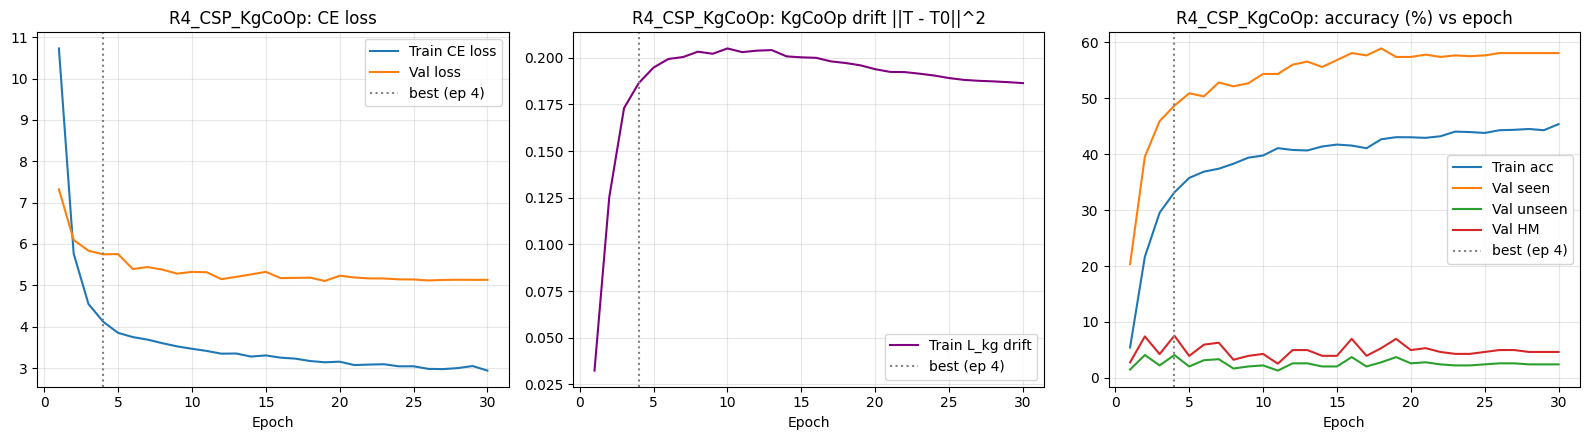


R4_CSP_KgCoOp unseen test | top1 2.28% | top5 19.75% | crop acc 57.46% | disease acc 9.12%
Error breakdown (% of images):
both right             2.28
crop wrong only        6.84
disease wrong only    55.18
both wrong            35.70

10 weakest compositions:
                        true   n  acc
          cherry / aphis_spp  72  0.0
           corn / brown_spot  35  0.0
   cotton / bacterial_blight 125  0.0
     cucumber / downy_mildew  32  0.0
         mango / anthracnose  95  0.0
       tomato / early_blight 472  2.3
pepper_bell / bacterial_spot 220  2.7
           grape / black_rot 271  3.0
            sugarcane / rust  89  3.4
   cucumber / powdery_mildew  37 13.5

Most frequent confusions:
                        true                        pred  count
       tomato / early_blight tomato / septoria_leaf_spot    135
           grape / black_rot                grape / esca    114
       tomato / early_blight        tomato / late_blight     65
       tomato / early_blight        to

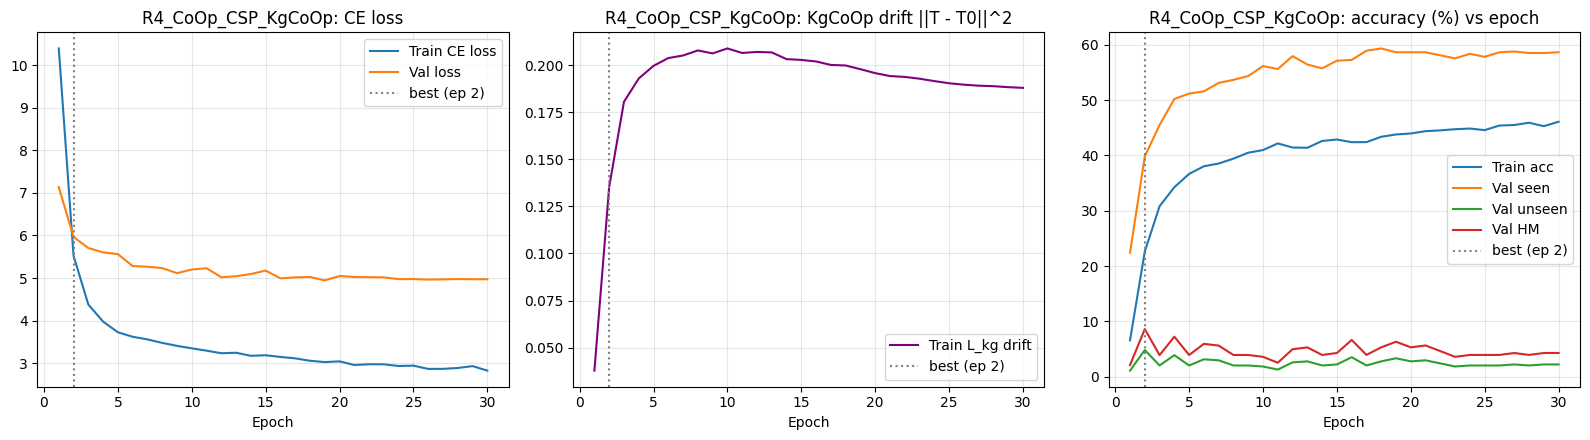


R4_CoOp_CSP_KgCoOp unseen test | top1 3.87% | top5 24.38% | crop acc 56.49% | disease acc 10.08%
Error breakdown (% of images):
both right             3.87
crop wrong only        6.22
disease wrong only    52.62
both wrong            37.29

10 weakest compositions:
                        true   n  acc
          cherry / aphis_spp  72  0.0
   cotton / bacterial_blight 125  0.0
     cucumber / downy_mildew  32  0.0
         mango / anthracnose  95  0.0
pepper_bell / bacterial_spot 220  2.3
           corn / brown_spot  35  2.9
            sugarcane / rust  89  3.4
           grape / black_rot 271  5.2
       tomato / early_blight 472  5.5
   cucumber / powdery_mildew  37 18.9

Most frequent confusions:
                        true                        pred  count
       tomato / early_blight tomato / septoria_leaf_spot    130
           grape / black_rot                grape / esca    121
       tomato / early_blight        tomato / late_blight     85
       tomato / early_blight    

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

cname = lambda c, d: f"{CROPS[c]} / {DISS[d]}"

def report(row, split="unseen", top_k=10):
    R = LAST[row]; hc, hd, H = R["hc"], R["hd"], pd.DataFrame(R["hist"]).set_index("epoch")
    X, df = (feats[split][:, 0], te_u) if split == "unseen" else (feats[split][:, 0], te_s)
    out = f"{RUNS}/{row}"; os.makedirs(out, exist_ok=True)

    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(16, 4.5))
    a1.plot(H.train_loss, label="Train CE loss"); a1.plot(H.val_loss, label="Val loss"); a1.set_title(f"{row}: CE loss")
    if "train_kg" in H:
        a2.plot(H.train_kg, color="purple", label="Train L_kg drift"); a2.set_title(f"{row}: KgCoOp drift ||T - T0||^2")
    for c_, lab in (("train_acc", "Train acc"), ("val_seen", "Val seen"), ("val_unseen", "Val unseen"), ("val_hm", "Val HM")):
        a3.plot(100 * H[c_], label=lab)
    a3.set_title(f"{row}: accuracy (%) vs epoch")
    for a in (a1, a2, a3):
        a.axvline(R["ep"], color="gray", ls=":", label=f"best (ep {R['ep']})")
        a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(f"{out}/curves.png", dpi=150); plt.show()

    with torch.no_grad():
        lc, ld = logp(hc, hd, X.to(dev))
    yc_, yd_ = df.crop_id.values, df.dis_id.values
    g = t(yc_ * ND + yd_); sc = (lc[:, :, None] + ld[:, None, :]).flatten(1)
    rank = ((sc > sc.gather(1, g[:, None])).sum(1) + 1).cpu().numpy()
    conf = sc.max(1).values.exp().cpu().numpy()
    pc, pdis = lc.argmax(1).cpu().numpy(), ld.argmax(1).cpu().numpy()
    ok = (pc == yc_) & (pdis == yd_); cw, dw = pc != yc_, pdis != yd_
    print(f"\n{row} {split} test | top1 {ok.mean():.2%} | top5 {(rank <= 5).mean():.2%} | "
          f"crop acc {1 - cw.mean():.2%} | disease acc {1 - dw.mean():.2%}")
    br = pd.Series({"both right": ~cw & ~dw, "crop wrong only": cw & ~dw,
                    "disease wrong only": ~cw & dw, "both wrong": cw & dw}).apply(np.mean) * 100
    print("Error breakdown (% of images):\n" + br.round(2).to_string())

    I = pd.DataFrame({"image": df.img.values, "true": [cname(c, d) for c, d in zip(yc_, yd_)],
                      "pred": [cname(c, d) for c, d in zip(pc, pdis)], "correct": ok,
                      "confidence_%": np.round(100 * conf, 2), "true_comp_rank": rank})
    I.to_csv(f"{out}/{split}_predictions.csv", index=False)
    pcmp = I.groupby("true").agg(n=("correct", "size"), acc=("correct", "mean")).reset_index().sort_values("acc")
    pcmp.to_csv(f"{out}/{split}_per_composition.csv", index=False)
    print(f"\n{top_k} weakest compositions:\n" + pcmp.head(top_k).assign(acc=lambda d: (100 * d.acc).round(1)).to_string(index=False))

    conf_df = I[~I.correct].groupby(["true", "pred"]).size().sort_values(ascending=False).head(15).rename("count").reset_index()
    conf_df.to_csv(f"{out}/{split}_top_confusions.csv", index=False)
    print("\nMost frequent confusions:\n" + conf_df.to_string(index=False))

report("R4_CSP_KgCoOp")
if "R4_CoOp_CSP_KgCoOp" in LAST:
    report("R4_CoOp_CSP_KgCoOp")

# Summary table across all rows in runs.csv (handles both 3-seed rows and single-seed 42 rows cleanly)
df_runs = pd.read_csv(f"{RUNS}/runs.csv")
pct_cols = ["val_hm", "test_seen_top1", "test_unseen_top1", "test_hm",
            "test_seen_top5", "test_unseen_top5", "crop_acc_u", "dis_acc_u", "bal_unseen"]
summary = {}
for row, g in df_runs.groupby("row", sort=False):
    rec = {"seeds": "/".join(str(int(s)) for s in g["seed"])}
    for c in pct_cols:
        rec[c] = f"{100 * g[c].mean():.2f}" if len(g) == 1 else f"{100 * g[c].mean():.2f} +- {100 * g[c].std():.2f}"
    rec["ausuc"] = f"{g['ausuc'].mean():.3f}" if len(g) == 1 else f"{g['ausuc'].mean():.3f} +- {g['ausuc'].std():.3f}"
    rec["epochs"] = "/".join(str(int(e)) for e in g["epochs_run"])
    summary[row] = rec

print("\n=== ABLATION SUMMARY TABLE ===")
print(pd.DataFrame(summary).T.to_string())

#### 10. Hyperparameter Refinement — `R4_CSP_KgCoOp` with Stronger Anchor ($\lambda_{kg} = 25.0$, $\text{lr} = 5\times 10^{-5}$)
Clamps the KgCoOp semantic drift $\mathcal{L}_{kg}$ inside the safe cone ($\le 0.13$) across all 30 epochs by pairing a gentler prompt learning rate (`5e-5`) with a stronger anchor penalty (`lambda_kg = 25.0`).


===== R4_CSP_KgCoOp_kg25 (seed 42): dev fit on train, epoch picked by val HM =====
[R4_CSP_KgCoOp_kg25 s42] trainable params: 325,120 | lambda_kg=25.0
[R4_CSP_KgCoOp_kg25 s42  1/30] ce=12.074 kg=0.0102 tr_acc=2.42% | val_loss=8.676 val_s=10.65% val_u=2.42% val_hm=3.94% *
[R4_CSP_KgCoOp_kg25 s42  2/30] ce=7.394 kg=0.0452 tr_acc=13.38% | val_loss=7.245 val_s=24.76% val_u=2.23% val_hm=4.09% *
[R4_CSP_KgCoOp_kg25 s42  3/30] ce=6.035 kg=0.0620 tr_acc=20.18% | val_loss=6.728 val_s=30.29% val_u=2.04% val_hm=3.83%
[R4_CSP_KgCoOp_kg25 s42  4/30] ce=5.542 kg=0.0683 tr_acc=23.25% | val_loss=6.565 val_s=34.16% val_u=2.42% val_hm=4.51% *
[R4_CSP_KgCoOp_kg25 s42  5/30] ce=5.240 kg=0.0712 tr_acc=25.58% | val_loss=6.526 val_s=35.55% val_u=1.67% val_hm=3.20%
[R4_CSP_KgCoOp_kg25 s42  6/30] ce=5.147 kg=0.0734 tr_acc=26.19% | val_loss=6.253 val_s=35.41% val_u=2.60% val_hm=4.85% *
[R4_CSP_KgCoOp_kg25 s42  7/30] ce=5.063 kg=0.0743 tr_acc=27.16% | val_loss=6.223 val_s=39.28% val_u=3.72% val_hm=6.79% *
[R4_C

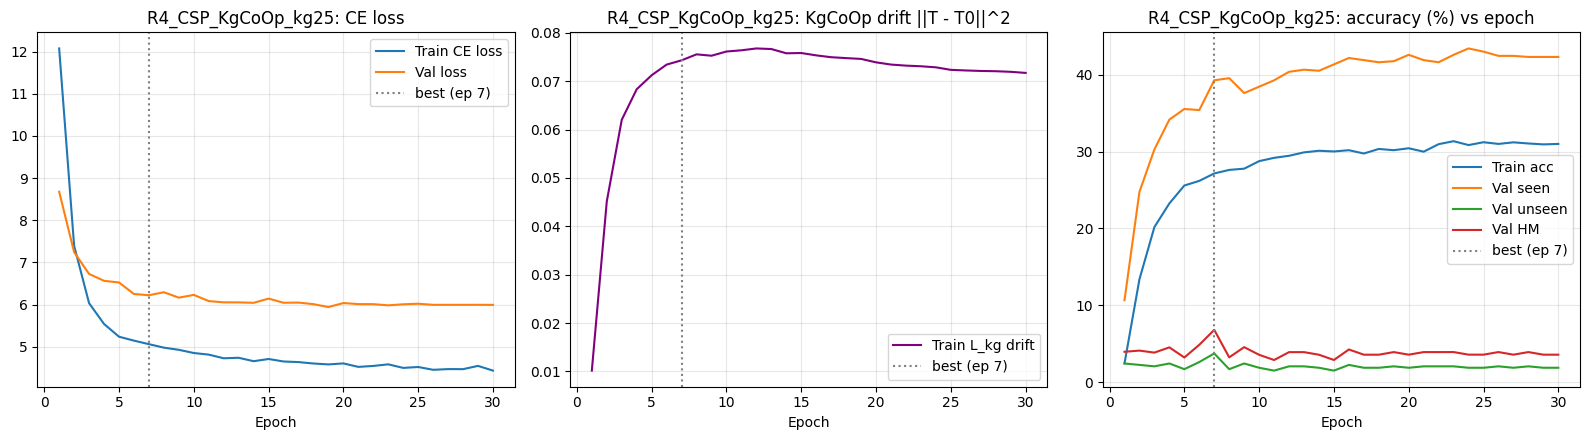


R4_CSP_KgCoOp_kg25 unseen test | top1 4.77% | top5 25.55% | crop acc 52.07% | disease acc 9.74%
Error breakdown (% of images):
both right             4.77
crop wrong only        4.97
disease wrong only    47.31
both wrong            42.96

10 weakest compositions:
                        true   n  acc
          cherry / aphis_spp  72  0.0
           corn / brown_spot  35  0.0
   cotton / bacterial_blight 125  0.0
     cucumber / downy_mildew  32  0.0
         mango / anthracnose  95  0.0
pepper_bell / bacterial_spot 220  0.5
            sugarcane / rust  89  5.6
           grape / black_rot 271  6.3
       tomato / early_blight 472  8.7
   cucumber / powdery_mildew  37 13.5

Most frequent confusions:
                        true                        pred  count
       tomato / early_blight tomato / septoria_leaf_spot    123
           grape / black_rot                grape / esca    107
       tomato / early_blight        tomato / late_blight     89
       tomato / early_blight     

In [10]:
CFG["csp_lr"] = 5e-5
CFG["lambda_kg"] = 25.0

run_row(
    "R4_CSP_KgCoOp_kg25",
    "csp_primitive_tokens_kgcoop25_lr5e5_s42",
    csp_kg_heads,
    extra={
        "tune_theta": True,
        "tune_ctx": False,
        "csp_lr": 5e-5,
        "lambda_kg": 25.0,
    },
)

report("R4_CSP_KgCoOp_kg25")

df_runs = pd.read_csv(f"{RUNS}/runs.csv")
pct_cols = [
    "val_hm",
    "test_seen_top1",
    "test_unseen_top1",
    "test_hm",
    "test_seen_top5",
    "test_unseen_top5",
    "crop_acc_u",
    "dis_acc_u",
    "bal_unseen",
]
summary = {}
for row, g in df_runs.groupby("row", sort=False):
    rec = {"seeds": "/".join(str(int(s)) for s in g["seed"])}
    for c in pct_cols:
        rec[c] = (
            f"{100 * g[c].mean():.2f}"
            if len(g) == 1
            else f"{100 * g[c].mean():.2f} +- {100 * g[c].std():.2f}"
        )
    rec["ausuc"] = (
        f"{g['ausuc'].mean():.3f}"
        if len(g) == 1
        else f"{g['ausuc'].mean():.3f} +- {g['ausuc'].std():.3f}"
    )
    rec["epochs"] = "/".join(str(int(e)) for e in g["epochs_run"])
    summary[row] = rec

print("\n=== ABLATION SUMMARY TABLE ===")
print(pd.DataFrame(summary).T.to_string())